This notebook provides examples to go along with the [textbook](https://underactuated.csail.mit.edu/acrobot.html).  I recommend having both windows open, side-by-side!


In [1]:
import sys

if "google.colab" in sys.modules:
    %pip install -q "underactuated[all]>=2026.9.8"

In [2]:
import numpy as np
from pydrake.all import (
    ControllabilityMatrix,
    DiagramBuilder,
    Linearize,
    LinearQuadraticRegulator,
    MeshcatVisualizer,
    Saturation,
    SceneGraph,
    Simulator,
    WrapToSystem,
)
from pydrake.examples import AcrobotGeometry, AcrobotInput, AcrobotPlant, AcrobotState

from underactuated import running_as_notebook
from underactuated.meshcat_utils import MeshcatSliders, StartMeshcat

In [3]:
# Start the visualizer (run this cell only once, each instance consumes a port)
meshcat = StartMeshcat()

INFO:drake:Meshcat listening for connections at http://localhost:7003


# Dynamics of the Acrobot

The acrobot is a core example in Drake.  We could certainly load it from a .urdf file, but Drake offers an Acrobot implementation that makes it convenient to manipulate the parameters (and visualize the system with different parameters).

In [4]:
def acrobot_demo():
    builder = DiagramBuilder()
    acrobot = builder.AddSystem(AcrobotPlant())

    # Setup visualization
    scene_graph = builder.AddSystem(SceneGraph())
    AcrobotGeometry.AddToBuilder(builder, acrobot.get_output_port(0), scene_graph)
    meshcat.Delete()
    meshcat.Set2dRenderMode(xmin=-4, xmax=4, ymin=-4, ymax=4)
    MeshcatVisualizer.AddToBuilder(builder, scene_graph, meshcat)

    # Clear controls left over from a previous (possibly interrupted) run so
    # that re-running this cell does not fail with "slider already exists".
    meshcat.DeleteAddedControls()

    # Setup slider input
    meshcat.AddSlider(
        "u",
        min=-5,
        max=5,
        step=0.1,
        value=0.0,
        decrement_keycode="ArrowLeft",
        increment_keycode="ArrowRight",
    )
    torque_system = builder.AddSystem(MeshcatSliders(meshcat, ["u"]))
    builder.Connect(torque_system.get_output_port(), acrobot.get_input_port())

    diagram = builder.Build()

    # Set up a simulator to run this diagram
    simulator = Simulator(diagram)
    context = simulator.get_mutable_context()

    # Set the initial conditions (theta1, theta2, theta1dot, theta2dot)
    context.SetContinuousState([1, 0, 0, 0])

    if running_as_notebook:  # Then we're not just running as a test on CI.
        simulator.set_target_realtime_rate(1.0)

        print("Use the slider in the MeshCat controls to apply elbow torque.")
        print("Press 'Stop Simulation' in MeshCat to continue.")
        meshcat.AddButton("Stop Simulation")
        while meshcat.GetButtonClicks("Stop Simulation") < 1:
            simulator.AdvanceTo(simulator.get_context().get_time() + 1.0)
    else:
        simulator.AdvanceTo(0.1)

    meshcat.DeleteAddedControls()


acrobot_demo()

Use the slider in the MeshCat controls to apply elbow torque.
Press 'Stop Simulation' in MeshCat to continue.


KeyboardInterrupt: 

# LQR for the Acrobot

First let's check the controllability.  Recall that the rank of the matrix is the number of of non-zero singular values.  So seeing very small singular values suggests "weak" controllability.

In [5]:
def UprightState():
    state = AcrobotState()
    state.set_theta1(np.pi)
    state.set_theta2(0.0)
    state.set_theta1dot(0.0)
    state.set_theta2dot(0.0)
    return state


def acrobot_controllability():
    acrobot = AcrobotPlant()
    context = acrobot.CreateDefaultContext()

    input = AcrobotInput()
    input.set_tau(0.0)
    acrobot.get_input_port(0).FixValue(context, input)

    context.get_mutable_continuous_state_vector().SetFromVector(
        UprightState().CopyToVector()
    )

    linearized_acrobot = Linearize(acrobot, context)
    print(
        f"The singular values of the controllability matrix are: {np.linalg.svd(ControllabilityMatrix(linearized_acrobot), compute_uv=False)}"
    )


acrobot_controllability()

The singular values of the controllability matrix are: [5.11718692e+02 1.23084288e+02 8.06819874e-02 7.15326677e-02]


In [6]:
def acrobot_balancing_example():
    def BalancingLQR():
        # Design an LQR controller for stabilizing the Acrobot around the upright.
        # Returns a (static) AffineSystem that implements the controller (in
        # the original AcrobotState coordinates).

        acrobot = AcrobotPlant()
        context = acrobot.CreateDefaultContext()

        input = AcrobotInput()
        input.set_tau(0.0)
        acrobot.get_input_port(0).FixValue(context, input)

        context.get_mutable_continuous_state_vector().SetFromVector(
            UprightState().CopyToVector()
        )

        Q = np.diag((10.0, 10.0, 1.0, 1.0))
        R = [1]

        return LinearQuadraticRegulator(acrobot, context, Q, R)

    builder = DiagramBuilder()
    acrobot = builder.AddSystem(AcrobotPlant())

    saturation = builder.AddSystem(Saturation(min_value=[-10], max_value=[10]))
    builder.Connect(saturation.get_output_port(0), acrobot.get_input_port(0))
    wrapangles = WrapToSystem(4)
    wrapangles.set_interval(0, 0, 2.0 * np.pi)
    wrapangles.set_interval(1, -np.pi, np.pi)
    wrapto = builder.AddSystem(wrapangles)
    builder.Connect(acrobot.get_output_port(0), wrapto.get_input_port(0))
    controller = builder.AddSystem(BalancingLQR())
    builder.Connect(wrapto.get_output_port(0), controller.get_input_port(0))
    builder.Connect(controller.get_output_port(0), saturation.get_input_port(0))

    # Setup visualization
    scene_graph = builder.AddSystem(SceneGraph())
    AcrobotGeometry.AddToBuilder(builder, acrobot.get_output_port(0), scene_graph)
    meshcat.Delete()
    meshcat.Set2dRenderMode(xmin=-4, xmax=4, ymin=-4, ymax=4)
    MeshcatVisualizer.AddToBuilder(builder, scene_graph, meshcat)

    diagram = builder.Build()

    # Set up a simulator to run this diagram
    simulator = Simulator(diagram)
    context = simulator.get_mutable_context()

    # Simulate
    simulator.set_target_realtime_rate(1.0 if running_as_notebook else 0.0)
    duration = 4.0 if running_as_notebook else 0.1
    for i in range(5):
        context.SetTime(0.0)
        context.SetContinuousState(
            UprightState().CopyToVector()
            + 0.05
            * np.random.randn(
                4,
            )
        )
        simulator.Initialize()
        simulator.AdvanceTo(duration)


acrobot_balancing_example()

# 作业分析（在课程原代码之后新增）

本文件是 `Exp3'1-acrobot.ipynb` 的**副本**：上方课程原始 cell 保持不变，下面追加作业要求的运行结果解读与参数敏感性分析。

- 原文件未被修改，可随时回退；
- 下面的 cell 只依赖 Drake，不依赖上方的 MeshCat 窗口，可单独运行；
- 结果与 `Exp1-acrobot-作业解答.md`、`exp1_analysis/exp1_analysis.py` 一致。

> 若点击 “Run All”，上方 cell 5 会等待 MeshCat 页面里的 “Stop Simulation” 按钮，这是原代码的交互设计。


In [7]:

# ===== 本节公共函数（独立于上方课程代码）=====
import numpy as np
import scipy.linalg as sla
import matplotlib.pyplot as plt
from pydrake.all import (
    ControllabilityMatrix, DiagramBuilder, Linearize, LinearQuadraticRegulator,
    Saturation, WrapToSystem, Simulator,
)
from pydrake.examples import AcrobotPlant, AcrobotInput
from pydrake.systems.primitives import LogVectorOutput

%matplotlib inline
plt.rcParams.update({
    "font.sans-serif": ["Arial Unicode MS", "Hiragino Sans GB"],
    "axes.unicode_minus": False,
    "figure.dpi": 120,
})
np.set_printoptions(precision=4, suppress=True, linewidth=180)

X_STAR = np.array([np.pi, 0.0, 0.0, 0.0])
BASE_Q = np.diag([10.0, 10.0, 1.0, 1.0])
BASE_R = np.array([[1.0]])
SAT, T = 10.0, 4.0
ANGLE_TOL, VEL_TOL = 0.05, 0.2


def a_wrap(a):
    return (a + np.pi) % (2.0 * np.pi) - np.pi


def a_plant_ctx(params_mod=None):
    plant = AcrobotPlant()
    ctx = plant.CreateDefaultContext()
    if params_mod:
        mp = plant.get_mutable_parameters(ctx)
        for k, v in params_mod.items():
            getattr(mp, f"set_{k}")(v)
    inp = AcrobotInput()
    inp.set_tau(0.0)
    plant.get_input_port(0).FixValue(ctx, inp)
    ctx.get_mutable_continuous_state_vector().SetFromVector(X_STAR)
    return plant, ctx


def a_lqr(params_mod=None, Q=BASE_Q, R=BASE_R):
    plant, ctx = a_plant_ctx(params_mod)
    return LinearQuadraticRegulator(plant, ctx, Q, R)


def a_linear(params_mod=None):
    plant, ctx = a_plant_ctx(params_mod)
    lin = Linearize(plant, ctx)
    A, B = lin.A(), lin.B()
    Cm = ControllabilityMatrix(lin).astype(float)
    sv = np.linalg.svd(Cm, compute_uv=False)
    lam, V = np.linalg.eig(A)
    beta = np.linalg.inv(V) @ B
    zeros = {}
    for name, cout in (("u->θ1", np.array([[1.0, 0, 0, 0]])),
                       ("u->θ2", np.array([[0.0, 1, 0, 0]]))):
        E = np.block([[np.eye(4), np.zeros((4, 1))],
                      [np.zeros((1, 4)), np.zeros((1, 1))]])
        M = np.block([[A, B], [cout, np.zeros((1, 1))]])
        z = sla.eigvals(M, E)
        zeros[name] = sorted(float(v.real) for v in z if np.isfinite(v))
    return dict(A=A, B=B, Cm=Cm, sv=sv, eig=lam, beta=beta.ravel(),
                zeros=zeros, rank=int(np.linalg.matrix_rank(Cm)))


def a_build(params_mod=None, Q=BASE_Q, R=BASE_R, sat_limit=SAT):
    controller = a_lqr(params_mod, Q, R)
    builder = DiagramBuilder()
    acrobot = builder.AddSystem(AcrobotPlant())
    sat = builder.AddSystem(Saturation([-sat_limit], [sat_limit]))
    builder.Connect(sat.get_output_port(0), acrobot.get_input_port(0))
    wraparound = WrapToSystem(4)
    wraparound.set_interval(0, 0.0, 2.0 * np.pi)
    wraparound.set_interval(1, -np.pi, np.pi)
    wrapto = builder.AddSystem(wraparound)
    builder.Connect(acrobot.get_output_port(0), wrapto.get_input_port(0))
    ctrl = builder.AddSystem(controller)
    builder.Connect(wrapto.get_output_port(0), ctrl.get_input_port(0))
    builder.Connect(ctrl.get_output_port(0), sat.get_input_port(0))
    log_x = LogVectorOutput(acrobot.get_output_port(0), builder, 0.01)
    log_u = LogVectorOutput(sat.get_output_port(0), builder, 0.01)
    log_ucmd = LogVectorOutput(ctrl.get_output_port(0), builder, 0.01)
    diagram = builder.Build()
    return dict(diagram=diagram, acrobot=acrobot, log_x=log_x, log_u=log_u,
                log_ucmd=log_ucmd, D=controller.D().ravel())


def a_sim(diag, params_mod, x0, T=T):
    sim = Simulator(diag["diagram"])
    ctx = sim.get_mutable_context()
    if params_mod:
        pctx = diag["diagram"].GetMutableSubsystemContext(diag["acrobot"], ctx)
        mp = diag["acrobot"].get_mutable_parameters(pctx)
        for k, v in params_mod.items():
            getattr(mp, f"set_{k}")(v)
    ctx.SetContinuousState(np.asarray(x0, float))
    sim.Initialize()
    sim.AdvanceTo(T)
    return (diag["log_x"].FindLog(ctx).sample_times().copy(),
            diag["log_x"].FindLog(ctx).data().copy(),
            diag["log_u"].FindLog(ctx).data().copy(),
            diag["log_ucmd"].FindLog(ctx).data().copy())


def a_metrics(ts, X, U, Uc):
    th1, th2 = a_wrap(X[0] - np.pi), a_wrap(X[1])
    w1, w2 = X[2], X[3]
    success = bool(abs(th1[-1]) < ANGLE_TOL and abs(th2[-1]) < ANGLE_TOL
                   and abs(w1[-1]) < VEL_TOL and abs(w2[-1]) < VEL_TOL)
    bad = ((np.abs(th1) > ANGLE_TOL) | (np.abs(th2) > ANGLE_TOL)
           | (np.abs(w1) > VEL_TOL) | (np.abs(w2) > VEL_TOL))
    settle = ((float(ts[np.where(bad)[0][-1] + 1]) if bad.any() else 0.0)
              if success else np.nan)
    early = ts < 0.5
    return dict(success=success, settle=settle,
                excursion=float(np.max(np.hypot(th1, th2))),
                peak_ucmd_early=float(np.max(np.abs(Uc[0][early]))))


def a_run(params_mod=None, Q=BASE_Q, R=BASE_R, sat_limit=SAT, x0s=None):
    diag = a_build(params_mod, Q, R, sat_limit)
    rows = [a_metrics(*a_sim(diag, params_mod, x0)) for x0 in x0s]
    return rows, diag


def a_summary(rows):
    ok = [r for r in rows if r["success"]]
    return dict(n=len(rows), success=int(sum(r["success"] for r in rows)),
                rate=float(np.mean([r["success"] for r in rows])),
                peak=float(np.median([r["peak_ucmd_early"] for r in rows])),
                excursion=float(np.median([r["excursion"] for r in rows])),
                settle=(float(np.nanmedian([r["settle"] for r in ok])) if ok else np.nan))


## 1. 线性化与可控性

计算 $A,B$、开环特征值、能控性矩阵的奇异值与模态参与因子，并给出 LQR 设计结果。

In [8]:

ld = a_linear()
ctrl = a_lqr()
D = ctrl.D().ravel()
A, B = ld["A"], ld["B"]
cl = np.linalg.eigvals(A + B @ D.reshape(1, -1))

print("Drake AcrobotPlant 默认参数：m1=m2=1, l1=1, l2=2, lc1=0.5, lc2=1, "
      "Ic1=0.083, Ic2=0.33, b1=b2=0.1, g=9.81\n")
print("A =\n", A)
print("B =", B.ravel())
print("\n开环特征值:", np.sort_complex(ld["eig"]))
print("rank(C) =", ld["rank"])
print("可控性矩阵奇异值 σ(C) =", ld["sv"])
print("条件数 σ_max/σ_min =", len(ld["sv"]) and ld["sv"][0] / ld["sv"][-1])
print("模态输入参与 |V^{-1}B| =", np.abs(ld["beta"]))
print("右半平面零点:", ld["zeros"])
print("\nLQR 反馈：u = D·(x - x*)，D =", D)
print("仿射补偿项 y0 =", float(ctrl.y0()[0]))
print("闭环极点:", np.sort_complex(cl))


Drake AcrobotPlant 默认参数：m1=m2=1, l1=1, l2=2, lc1=0.5, lc2=1, Ic1=0.083, Ic2=0.33, b1=b2=0.1, g=9.81

A =
 [[  0.       0.       1.       0.    ]
 [  0.       0.       0.       1.    ]
 [ 12.6292 -12.6926  -0.1721   0.3015]
 [-14.7488  29.6119   0.3015  -0.6033]]
B = [ 0.      0.     -3.0147  6.0332]

开环特征值: [-6.492 +0.j -2.2486+0.j  2.2314+0.j  5.7337+0.j]
rank(C) = 4
可控性矩阵奇异值 σ(C) = [511.7187 123.0843   0.0807   0.0715]
条件数 σ_max/σ_min = 7153.636350376389
模态输入参与 |V^{-1}B| = [3.6207 0.0481 3.2074 0.0484]
右半平面零点: {'u->θ1': [-2.0519016616749837, 2.051901661674984], 'u->θ2': [-2.3041054906783467, 2.282660069275817]}

LQR 反馈：u = D·(x - x*)，D = [278.4422 112.2913 119.7246  56.8282]
仿射补偿项 y0 = -874.7520681690859
闭环极点: [-10.1259+0.j      -4.2381+0.j      -2.2421-0.0387j  -2.2421+0.0387j]


## 2. LQR 镇定与输入饱和

与 notebook cell 9 相同的 `Q`、`R`、±10 N·m 饱和和 4 s 仿真时域，统计 100 次随机扰动。

In [9]:

# 与 notebook 相同的设置：x0 = x* + 0.05*N(0,I4)，仿真 4 s
rng = np.random.default_rng(42)
x0s100 = [X_STAR + 0.05 * rng.standard_normal(4) for _ in range(100)]

rows10, _ = a_run(x0s=x0s100, sat_limit=SAT)
rowsU, _ = a_run(x0s=x0s100, sat_limit=1e6)

for name, rows in [("|τ| ≤ 10 N·m", rows10), ("无输入饱和", rowsU)]:
    s = a_summary(rows)
    print(f"{name:12s} 成功率 {s['success']:3d}/{s['n']} = {s['rate']:.0%} | "
          f"前 0.5 s 峰值指令中位数 {s['peak']:5.1f} N·m | "
          f"最大角度偏离中位数 {s['excursion']:.2f} rad | "
          f"调节时间中位数 {s['settle']:.2f} s")

# notebook cell 9 只跑 5 次，这里固定随机种子复现一次作对照
rng5 = np.random.default_rng(7)
rows5, _ = a_run(x0s=[X_STAR + 0.05 * rng5.standard_normal(4) for _ in range(5)],
                 sat_limit=SAT)
s5 = a_summary(rows5)
print(f"\nnotebook 5 次试验复现：成功率 {s5['success']}/5 = {s5['rate']:.0%} "
      f"（单次结果随机波动大，属正常）")


|τ| ≤ 10 N·m 成功率  63/100 = 63% | 前 0.5 s 峰值指令中位数  11.2 N·m | 最大角度偏离中位数 0.86 rad | 调节时间中位数 1.63 s
无输入饱和        成功率  98/100 = 98% | 前 0.5 s 峰值指令中位数  11.2 N·m | 最大角度偏离中位数 0.85 rad | 调节时间中位数 1.67 s

notebook 5 次试验复现：成功率 4/5 = 80% （单次结果随机波动大，属正常）


## 3.1 敏感性：初始扰动尺度 δ

固定控制器，只改变初始扰动幅度；对比有/无输入饱和。

     δ    ±10 N·m        无饱和          峰值指令中位数
 0.005       100%       100%           1.2 N·m
 0.010       100%       100%           2.4 N·m
 0.020       100%       100%           4.8 N·m
 0.030        88%       100%           7.1 N·m
 0.050        70%       100%          11.9 N·m
 0.075        54%        98%          20.6 N·m
 0.100        42%        92%          26.4 N·m
 0.150        32%        82%         444.9 N·m
 0.200        18%        60%         447.2 N·m


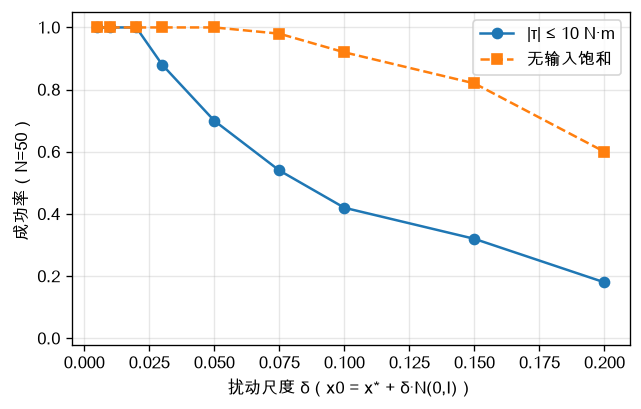

In [10]:

deltas = [0.005, 0.01, 0.02, 0.03, 0.05, 0.075, 0.1, 0.15, 0.2]
rng = np.random.default_rng(43)
draws = [rng.standard_normal(4) for _ in range(50)]

res = []
print(f"{'δ':>6} {'±10 N·m':>10} {'无饱和':>10} {'峰值指令中位数':>16}")
for d in deltas:
    x0s = [X_STAR + d * w for w in draws]
    r10 = a_summary(a_run(x0s=x0s, sat_limit=SAT)[0])
    ru = a_summary(a_run(x0s=x0s, sat_limit=1e6)[0])
    res.append((d, r10["rate"], ru["rate"], r10["peak"]))
    print(f"{d:6.3f} {r10['rate']:10.0%} {ru['rate']:10.0%} {r10['peak']:13.1f} N·m")

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot([r[0] for r in res], [r[1] for r in res], "o-", label="|τ| ≤ 10 N·m")
ax.plot([r[0] for r in res], [r[2] for r in res], "s--", label="无输入饱和")
ax.set_xlabel("扰动尺度 δ（x0 = x* + δ·N(0,I)）")
ax.set_ylabel("成功率（N=50）")
ax.set_ylim(-0.02, 1.05)
ax.grid(alpha=0.3)
ax.legend()
plt.show()


## 3.2 敏感性：LQR 权重 R 与 Q

观察控制代价与状态代价对增益、峰值力矩和成功率的影响。

R 扫描（Q 固定为 diag(10,10,1,1)）：
      R      ‖D‖      成功率          峰值指令中位数
    0.1    577.1      65%          19.8 N·m
    1.0    328.2      63%          11.2 N·m
   10.0    289.7      62%           9.8 N·m
  100.0    285.5      62%           9.7 N·m

Q 角度权重扫描（Q = diag(w,w,1,1), R = 1）：
      w      ‖D‖      成功率          峰值指令中位数
    1.0    303.9      65%          10.3 N·m
   10.0    328.2      63%          11.2 N·m
  100.0    488.9      61%          16.8 N·m


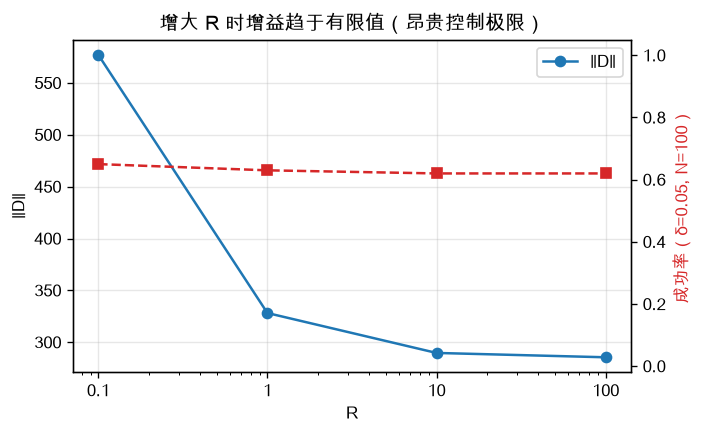

In [11]:

rng = np.random.default_rng(42)
x0s = [X_STAR + 0.05 * rng.standard_normal(4) for _ in range(100)]

print("R 扫描（Q 固定为 diag(10,10,1,1)）：")
print(f"{'R':>7} {'‖D‖':>8} {'成功率':>8} {'峰值指令中位数':>16}")
r_rows = []
for R in [0.1, 1.0, 10.0, 100.0]:
    rows, _ = a_run(R=np.array([[R]]), x0s=x0s, sat_limit=SAT)
    c = a_lqr(R=np.array([[R]]))
    s = a_summary(rows)
    r_rows.append((R, float(np.linalg.norm(c.D())), s["rate"], s["peak"]))
    print(f"{R:7.1f} {r_rows[-1][1]:8.1f} {s['rate']:8.0%} {s['peak']:13.1f} N·m")

print("\nQ 角度权重扫描（Q = diag(w,w,1,1), R = 1）：")
print(f"{'w':>7} {'‖D‖':>8} {'成功率':>8} {'峰值指令中位数':>16}")
for w in [1.0, 10.0, 100.0]:
    rows, _ = a_run(Q=np.diag([w, w, 1.0, 1.0]), x0s=x0s, sat_limit=SAT)
    c = a_lqr(Q=np.diag([w, w, 1.0, 1.0]))
    s = a_summary(rows)
    print(f"{w:7.1f} {np.linalg.norm(c.D()):8.1f} {s['rate']:8.0%} {s['peak']:13.1f} N·m")

fig, ax = plt.subplots(figsize=(6, 3.6))
Rs = [r[0] for r in r_rows]
ax.plot(Rs, [r[1] for r in r_rows], "o-", label="‖D‖")
ax.set_xscale("log")
ax.set_xticks(Rs)
ax.set_xticklabels(["0.1", "1", "10", "100"])
ax.set_xlabel("R")
ax.set_ylabel("‖D‖")
ax.grid(alpha=0.3)
ax.legend(loc="upper right")
ax2 = ax.twinx()
ax2.plot(Rs, [r[2] for r in r_rows], "s--", color="tab:red", label="成功率")
ax2.set_ylabel("成功率（δ=0.05, N=100）", color="tab:red")
ax2.set_ylim(-0.02, 1.05)
ax.set_title("增大 R 时增益趋于有限值（昂贵控制极限）")
plt.show()


## 3.3 敏感性：物理参数 m2 与 lc2

改变末端质量和质心距，观察可控性指标与饱和 LQR 的实际成功率。


m2 扫描：
   m2     σ_min(C)      cond(C)      ‖D‖      成功率         峰值指令
  0.5       0.2067         1521    153.2      98%       5.1 N·m
  1.0       0.0715         7154    328.2      63%      11.2 N·m
  2.0       0.0215        42405    864.3      35%      47.8 N·m
  4.0       0.0059       289092   2655.7      10%     317.0 N·m

lc2 扫描：
  lc2     σ_min(C)      cond(C)      ‖D‖      成功率         峰值指令
  0.5       0.1790         1379    222.8      70%       7.4 N·m
  1.0       0.0715         7154    328.2      63%      11.2 N·m
  1.5       0.0411        15191    418.7      62%      13.4 N·m


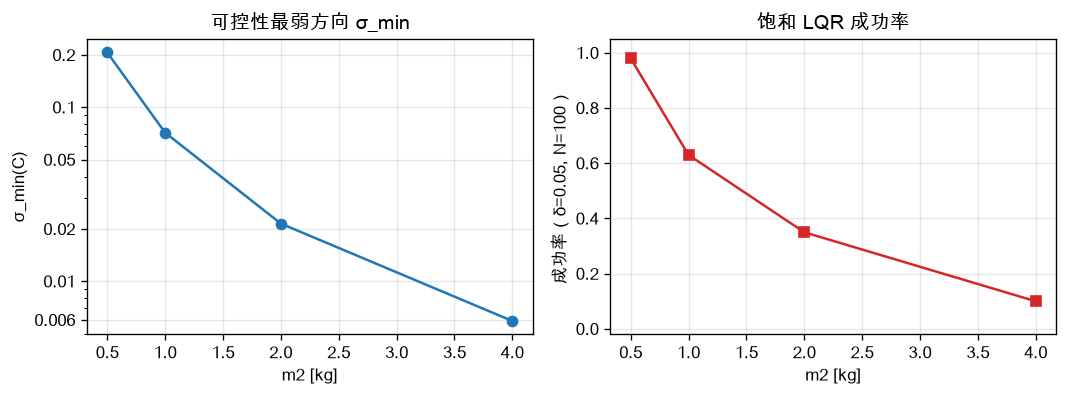

In [12]:

rng = np.random.default_rng(42)
x0s = [X_STAR + 0.05 * rng.standard_normal(4) for _ in range(100)]


def a_param_sweep(name, values):
    print(f"\n{name} 扫描：")
    print(f"{name:>5} {'σ_min(C)':>12} {'cond(C)':>12} {'‖D‖':>8} {'成功率':>8} {'峰值指令':>12}")
    out = []
    for v in values:
        mods = {name: v}
        rows, _ = a_run(params_mod=mods, x0s=x0s, sat_limit=SAT)
        ld = a_linear(mods)
        c = a_lqr(mods)
        s = a_summary(rows)
        out.append((v, ld["sv"][-1], float(np.linalg.norm(c.D())), s["rate"], s["peak"]))
        print(f"{v:5.1f} {ld['sv'][-1]:12.4f} {ld['sv'][0]/ld['sv'][-1]:12.0f} "
              f"{out[-1][2]:8.1f} {s['rate']:8.0%} {s['peak']:9.1f} N·m")
    return out


m2_rows = a_param_sweep("m2", [0.5, 1.0, 2.0, 4.0])
lc2_rows = a_param_sweep("lc2", [0.5, 1.0, 1.5])

fig, axs = plt.subplots(1, 2, figsize=(9, 3.4))
axs[0].plot([r[0] for r in m2_rows], [r[1] for r in m2_rows], "o-")
axs[0].set_xlabel("m2 [kg]")
axs[0].set_ylabel("σ_min(C)")
axs[0].set_yscale("log")
axs[0].set_yticks([0.2, 0.1, 0.05, 0.02, 0.01, 0.006])
axs[0].set_yticklabels(["0.2", "0.1", "0.05", "0.02", "0.01", "0.006"])
axs[0].grid(alpha=0.3)
axs[0].set_title("可控性最弱方向 σ_min")
axs[1].plot([r[0] for r in m2_rows], [r[3] for r in m2_rows], "s-", color="tab:red")
axs[1].set_xlabel("m2 [kg]")
axs[1].set_ylabel("成功率（δ=0.05, N=100）")
axs[1].set_ylim(-0.02, 1.05)
axs[1].grid(alpha=0.3)
axs[1].set_title("饱和 LQR 成功率")
plt.tight_layout()
plt.show()


## 4. 代表性轨迹：成功 vs 失败

两个初始偏差方向（均为 0.05 量级）导致完全不同的结果。

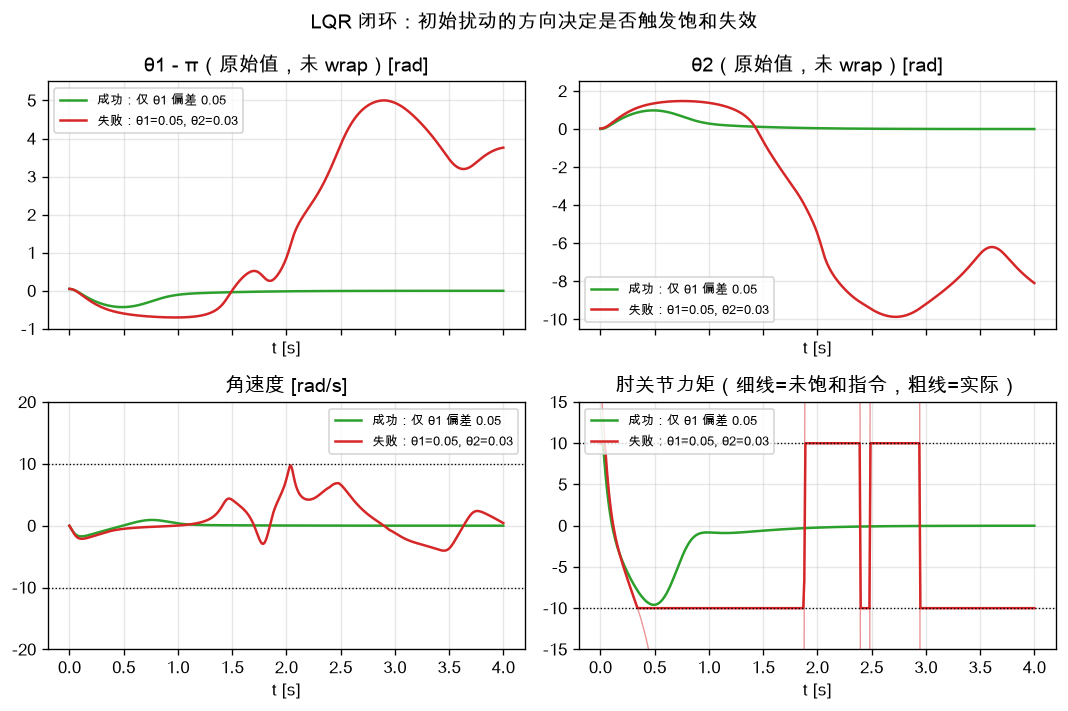

In [13]:

def a_plot_case(axs, ts, X, U, Uc, color, label):
    axs[0].plot(ts, X[0] - np.pi, color=color, label=label)
    axs[1].plot(ts, X[1], color=color, label=label)
    axs[2].plot(ts, X[2], color=color, label=label)
    axs[3].plot(ts, np.clip(Uc[0], -60, 60), color=color, lw=0.8, alpha=0.5)
    axs[3].plot(ts, U[0], color=color, label=label)


diag = a_build()
cases = [("成功：仅 θ1 偏差 0.05", X_STAR + np.array([0.05, 0.0, 0.0, 0.0]), "tab:green"),
         ("失败：θ1=0.05, θ2=0.03", X_STAR + np.array([0.05, 0.03, 0.0, 0.0]), "tab:red")]

fig, axs = plt.subplots(2, 2, figsize=(9, 6), sharex=True)
for label, x0, color in cases:
    ts, X, U, Uc = a_sim(diag, None, x0)
    a_plot_case([axs[0, 0], axs[0, 1], axs[1, 0], axs[1, 1]], ts, X, U, Uc, color, label)

for ax, ti in zip(axs.ravel(),
                  ["θ1 - π（原始值，未 wrap）[rad]", "θ2（原始值，未 wrap）[rad]",
                   "角速度 [rad/s]", "肘关节力矩 [N·m]"]):
    ax.set_title(ti)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
    ax.set_xlabel("t [s]")
axs[0, 0].set_ylim(-1.0, 5.5)
axs[0, 1].set_ylim(-10.5, 2.5)
axs[1, 0].set_ylim(-20, 20)
for ax in axs[1, :]:
    ax.axhline(10, color="k", ls=":", lw=0.8)
    ax.axhline(-10, color="k", ls=":", lw=0.8)
axs[1, 1].set_ylim(-15, 15)
axs[1, 1].set_title("肘关节力矩（细线=未饱和指令，粗线=实际）")
fig.suptitle("LQR 闭环：初始扰动的方向决定是否触发饱和失效")
fig.tight_layout()
plt.show()


## 结论速览

1. **可控性**：`rank(C)=4`，但奇异值为 `[511.7, 123.1, 0.0807, 0.0715]`，条件数约 7154；两个慢模态的输入参与因子只有约 0.05 —— **欠驱动但完全可控，且属于“弱可控”**。
2. **LQR**：`D=[278.4, 112.3, 119.7, 56.8]`，闭环极点全部在左半平面，局部指数稳定。
3. **饱和的影响**：无饱和时 100 次 0.05 级随机扰动中有 98 次成功；加入代码里的 ±10 N·m 饱和后只剩约 63 次。**LQR 的保证是局部的，输入饱和显著缩小吸引域**。
4. **非最小相位**：右半平面零点（+2.05、+2.28）使状态必须先大幅远离原点再回来（成功样本最大偏离中位数约 0.86 rad），这也是饱和更容易被触发的原因。
5. **敏感性**：成功率随扰动尺度增大而单调下降；增大 R 无法把增益降到很低（昂贵控制极限）；**末端质量 m2 最敏感**（0.5→4 kg 时 σ_min 下降约 35 倍，成功率 98%→10%）。
6. **工程含义**：实际 Acrobot 需先用能量整定把状态送入吸引域，再在顶端附近用局部控制器，并显式评估力矩上限与吸引域。

> 完整推导与表格见 `Exp1-acrobot-作业解答.md`；批量脚本见 `exp1_analysis/exp1_analysis.py`。
